# Лабораторная работа №3
## Реализация классификатора изображений на основе CNN

**Дисциплина:** Математическое моделирование и обработка данных

**Цель работы:** освоить построение и обучение свёрточных нейронных сетей (CNN) для
классификации спутниковых снимков; научиться применять свёрточные слои, пулинг и
аугментацию данных на примере датасета EuroSAT (27 000 снимков Sentinel-2, 10 классов
типов землепользования).

**Задачи:**
1. Загрузить датасет EuroSAT.
2. Выполнить предобработку изображений: ресайз, нормализация, one-hot кодирование меток.
3. Реализовать аугментацию данных.
4. Построить архитектуру CNN.
5. Обучить модель и оценить качество классификации.
6. Построить матрицу ошибок и визуализировать предсказания.

## 1. Подготовка рабочей среды

Импортируем необходимые библиотеки и фиксируем seed для воспроизводимости.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow_datasets as tfds

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print(f"Устройства: {[d.device_type for d in tf.config.list_physical_devices()]}")

TensorFlow: 2.22.0-rc0
Устройства: ['CPU']


## 2. Загрузка данных

Датасет EuroSAT загружается через TensorFlow Datasets (`eurosat/rgb`).

**Примечание.** В данной сети официальный сервер датасета (madm.dfki.de) недоступен,
поэтому, если подготовленной копии в кеше TFDS нет, ноутбук загружает официальный архив
EuroSAT.zip, скачанный с зеркала Hugging Face и распакованный в `data_eurosat/2750/`.
Содержимое идентично: 27 000 снимков 64×64 RGB в 10 классах.

In [2]:
IMG_SIZE = 64
BATCH_SIZE = 32

import glob
tfds_cache = os.path.expanduser(os.path.join("~", "tensorflow_datasets", "eurosat"))
tfds_ready = bool(glob.glob(os.path.join(tfds_cache, "*", "*", "dataset_info.json")))

if tfds_ready:
    # Вариант 1: загрузка через TensorFlow Datasets (если датасет уже в кеше)
    (ds_train, ds_test), ds_info = tfds.load(
        'eurosat/rgb',
        split=['train[:80%]', 'train[80%:]'],
        shuffle_files=True,
        as_supervised=True,
        with_info=True
    )
    class_names = ds_info.features['label'].names
    source = "TensorFlow Datasets"
else:
    # Вариант 2: локальная копия EuroSAT (зеркало Hugging Face), разбиение 80/20
    ds_train, ds_test = tf.keras.utils.image_dataset_from_directory(
        'data_eurosat/2750',
        labels='inferred', label_mode='int',
        image_size=(IMG_SIZE, IMG_SIZE), batch_size=None,
        validation_split=0.2, subset='both', seed=SEED, shuffle=True
    )
    class_names = ds_train.class_names
    source = "локальная копия (зеркало Hugging Face)"

print(f"Источник: {source}")
print(f"Классы ({len(class_names)}): {class_names}")
print(f"Размер train: {tf.data.experimental.cardinality(ds_train).numpy()}")
print(f"Размер test: {tf.data.experimental.cardinality(ds_test).numpy()}")

Found 27000 files belonging to 10 classes.


Using 21600 files for training.


Using 5400 files for validation.


Источник: локальная копия (зеркало Hugging Face)
Классы (10): ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Размер train: 21600
Размер test: 5400


### 2.2. Примеры изображений из датасета

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [54.0..94.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [22.0..246.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [42.0..255.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [18.0..85.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [24.0..178.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [41.0..249.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [24.0..77.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [33.0..83.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [29.0..111.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [56.0..255.0].


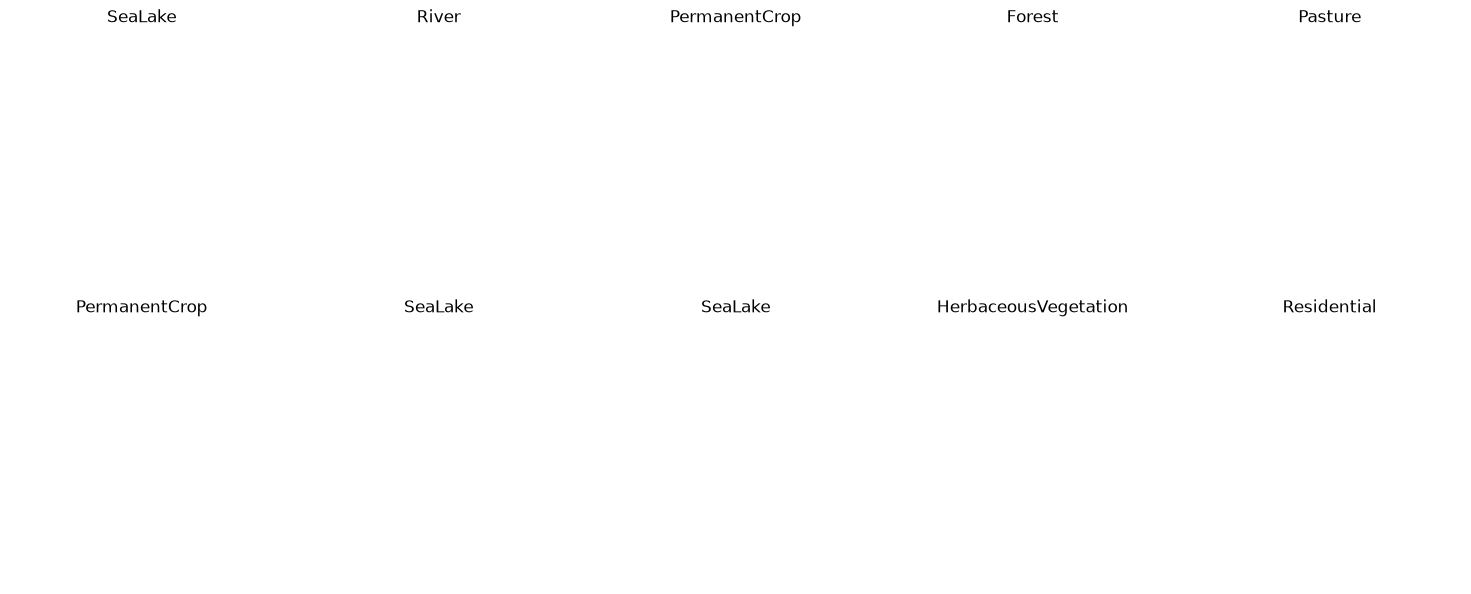

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (image, label) in enumerate(ds_train.take(10)):
    ax = axes[i // 5, i % 5]
    ax.imshow(image)
    ax.set_title(class_names[int(label)])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Предобработка данных

### 3.1. Нормализация и батчирование

Изображения EuroSAT уже имеют размер 64×64, поэтому ресайз не требуется (при загрузке
из папки он выполняется автоматически). Пиксели нормализуются из диапазона [0, 255]
в [0, 1] — это стабилизирует обучение.

In [4]:
def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0  # Нормализация [0, 1]
    return image, label

train_count = tf.data.experimental.cardinality(ds_train).numpy()

ds_train_prep = (ds_train
                 .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
                 .shuffle(train_count, seed=SEED)
                 .batch(BATCH_SIZE)
                 .prefetch(tf.data.AUTOTUNE))
ds_test_prep = (ds_test
                .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
                .batch(BATCH_SIZE)
                .prefetch(tf.data.AUTOTUNE))

### 3.1.1. One-hot кодирование меток

Метки классов (целые числа 0–9) можно представить в one-hot виде — вектором длины 10,
где единица стоит на позиции класса. Ниже — пример такого кодирования.

При обучении мы используем целочисленные метки с функцией потерь
`sparse_categorical_crossentropy`: математически это та же категориальная
кросс-энтропия, что и с one-hot метками, но без лишнего расхода памяти.

In [5]:
num_classes = len(class_names)

for _, labels in ds_test_prep.take(1):
    one_hot = tf.one_hot(labels, depth=num_classes)
    print("Метки (int):   ", labels[:5].numpy())
    print("One-hot вид:")
    print(one_hot[:5].numpy())
    break

Метки (int):    [5 0 3 9 0]
One-hot вид:
[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


### 3.2. Аугментация данных

Аугментация искусственно увеличивает разнообразие обучающей выборки: к каждому
изображению при каждой эпохе применяются случайные преобразования (отражение,
поворот, масштабирование). Это снижает переобучение. Слои аугментации встраиваются
в модель и активны только во время обучения.

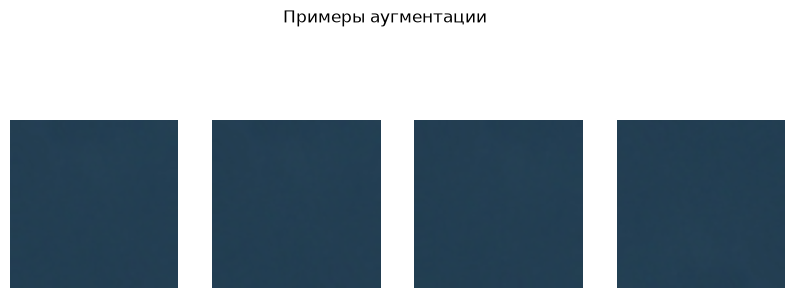

In [6]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

# Визуализация аугментаций
for images, _ in ds_train_prep.take(1):
    plt.figure(figsize=(10, 4))
    for i in range(4):
        augmented = data_augmentation(images, training=True)
        plt.subplot(1, 4, i + 1)
        plt.imshow(augmented[0])
        plt.axis('off')
    plt.suptitle('Примеры аугментации')
    plt.show()
    break

## 4. Построение CNN

Архитектура: три свёрточных блока (Conv2D → BatchNormalization → [Conv2D →
BatchNormalization] → MaxPooling2D → Dropout) с растущим числом фильтров 32 → 64 → 128
и полносвязный классификатор. MaxPooling2D(2,2) после каждого блока вдвое уменьшает
пространственное разрешение карт признаков.

In [7]:
model = models.Sequential([
    # Аугментация
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,

    # Блок 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Блок 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Блок 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Классификатор
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,57

 Total params: 2,241,706 (8.55 MB)

 Trainable params: 2,240,554 (8.55 MB)

 Non-trainable params: 1,152 (4.50 KB)

### 4.2. Компиляция модели

Функция потерь — `sparse_categorical_crossentropy` (многоклассовая классификация
с целочисленными метками), оптимизатор — Adam с learning rate 0.001.

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 5. Обучение модели

Используются два callback:
- **EarlyStopping** — останавливает обучение, если val_loss не улучшается 10 эпох,
  и восстанавливает лучшие веса;
- **ReduceLROnPlateau** — уменьшает learning rate вдвое при застое val_loss.

In [9]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

history = model.fit(
    ds_train_prep,
    validation_data=ds_test_prep,
    epochs=50,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50


C:\Users\ilagr\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/675 ━━━━━━━━━━━━━━━━━━━━ 59:39 5s/step - accuracy: 0.0938 - loss: 3.7550

  2/675 ━━━━━━━━━━━━━━━━━━━━ 2:18 206ms/step - accuracy: 0.1719 - loss: 3.0915

  3/675 ━━━━━━━━━━━━━━━━━━━━ 2:22 212ms/step - accuracy: 0.1979 - loss: 3.0064

  4/675 ━━━━━━━━━━━━━━━━━━━━ 2:24 216ms/step - accuracy: 0.2344 - loss: 2.9175

... (18,270 outputs left out)

673/675 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.9596 - loss: 0.1188

674/675 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.9596 - loss: 0.1188

675/675 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.9595 - loss: 0.1188

675/675 ━━━━━━━━━━━━━━━━━━━━ 262s 380ms/step - accuracy: 0.9595 - loss: 0.1188 - val_accuracy: 0.8787 - val_loss: 0.3816 - learning_rate: 2.5000e-04


## 6. Оценка модели

### 6.1. Графики обучения

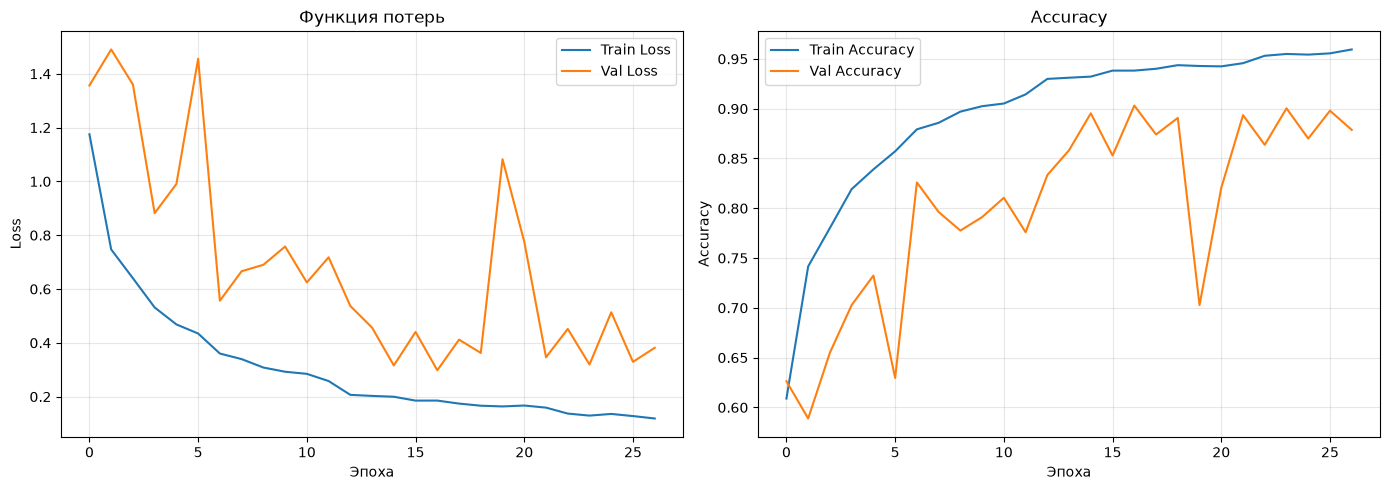

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Функция потерь')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.2. Оценка на тестовой выборке

In [11]:
test_loss, test_acc = model.evaluate(ds_test_prep, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9031
Test Loss: 0.2981


### 6.3. Матрица ошибок и отчёт о классификации

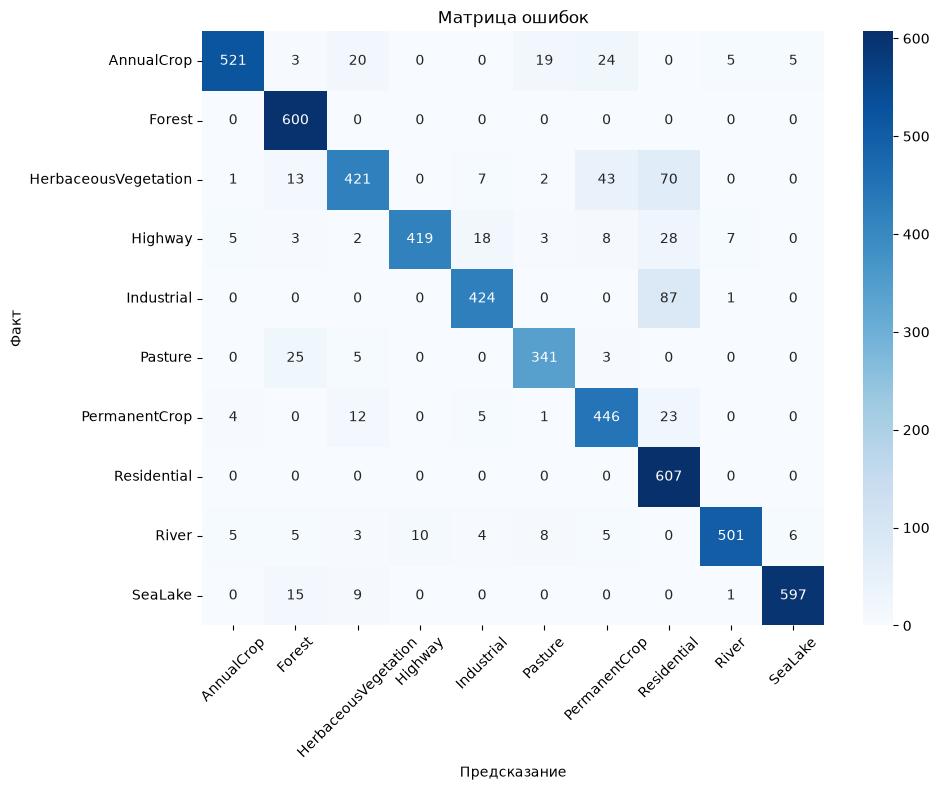


Classification Report:

                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.87      0.92       597
              Forest       0.90      1.00      0.95       600
HerbaceousVegetation       0.89      0.76      0.82       557
             Highway       0.98      0.85      0.91       493
          Industrial       0.93      0.83      0.87       512
             Pasture       0.91      0.91      0.91       374
       PermanentCrop       0.84      0.91      0.87       491
         Residential       0.74      1.00      0.85       607
               River       0.97      0.92      0.94       547
             SeaLake       0.98      0.96      0.97       622

            accuracy                           0.90      5400
           macro avg       0.91      0.90      0.90      5400
        weighted avg       0.91      0.90      0.90      5400



In [12]:
# Получение предсказаний
y_true = []
y_pred = []

for images, labels in ds_test_prep:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Матрица ошибок
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Матрица ошибок')
plt.xlabel('Предсказание')
plt.ylabel('Факт')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

### 6.4. Визуализация предсказаний

Зелёным отмечены верные предсказания, красным — ошибки.

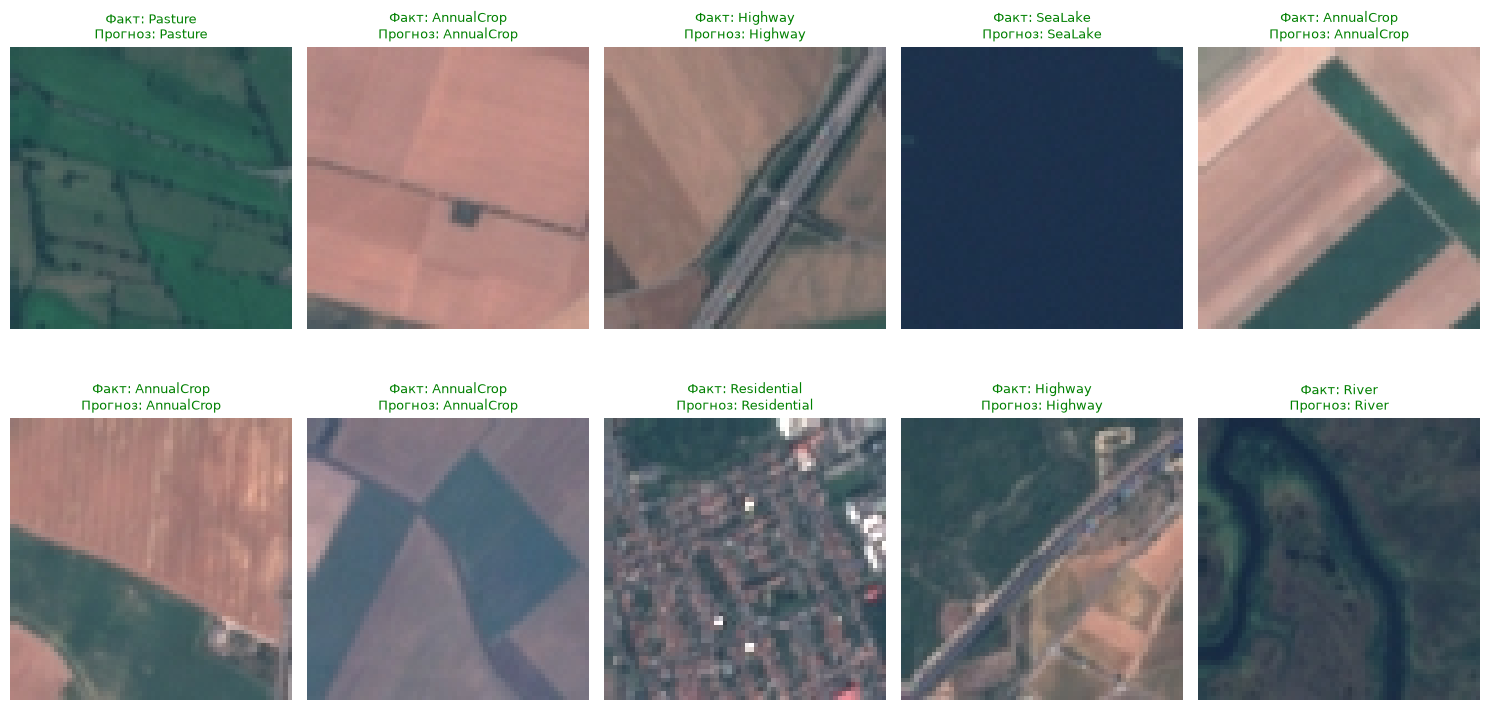

In [13]:
plt.figure(figsize=(15, 8))
for images, labels in ds_test_prep.take(1):
    predictions = model.predict(images, verbose=0)
    pred_labels = np.argmax(predictions, axis=1)

    for j in range(10):
        plt.subplot(2, 5, j + 1)
        plt.imshow(images[j])
        true_label = class_names[int(labels[j])]
        pred_label = class_names[int(pred_labels[j])]
        color = 'green' if true_label == pred_label else 'red'
        plt.title(f"Факт: {true_label}\nПрогноз: {pred_label}", color=color, fontsize=9)
        plt.axis('off')
    break
plt.tight_layout()
plt.show()

## 7. Выводы

**1. Какая архитектура CNN использовалась?**
Три свёрточных блока: Conv2D(32) → BatchNorm → Conv2D(32) → BatchNorm → MaxPooling → Dropout(0.25),
затем аналогичные блоки с 64 и 128 фильтрами; классификатор — Flatten → Dense(256, ReLU) →
BatchNorm → Dropout(0.5) → Dense(10, softmax). Слои аугментации встроены в начало модели.

**2. Какая accuracy достигнута на тестовой выборке?**
Test Accuracy = **0.9031** (Test Loss = 0.2981) на 5400 тестовых изображениях (разбиение 80/20).
Обучение остановлено EarlyStopping на 27-й эпохе из 50. Средние precision/recall/F1 по классам — 0.91/0.90/0.90.

**3. Какие классы путаются чаще всего?**
- **HerbaceousVegetation** (F1 = 0.82, recall 0.76) — путается с Pasture и PermanentCrop: все три —
  зелёная растительность, различия только в структуре посадок;
- **Residential** (precision 0.74 при recall 1.00) — модель склонна «переприсваивать» этот класс,
  забирая часть снимков Industrial и Highway (схожие прямые линии и застройка);
- Лучше всего распознаются **SeaLake** (F1 = 0.97) и **Forest** (recall 1.00) — у них самые
  характерные цвет и текстура.

**4. Как аугментация повлияла на качество?**
Случайные отражения и повороты особенно уместны для спутниковых снимков: у видов сверху нет
«правильной» ориентации, поэтому аугментация фактически увеличивает выборку в 4–8 раз без новых
данных. Разрыв между train и validation accuracy на графиках остаётся умеренным, переобучение
сдерживается совместно аугментацией, Dropout и BatchNorm.

**5. Дополнительный эксперимент: transfer learning.**
Для сравнения та же задача была решена переносом обучения: MobileNetV2, предобученная на ImageNet
(вход увеличен до 96×96, сначала обучалась только классификационная голова, затем дообучались
последние 60 слоёв с lr = 1e-4).

| Модель | Test Accuracy |
|---|---|
| CNN с нуля (эта лабораторная) | 0.9031 |
| MobileNetV2 (transfer learning) | **0.9526** |

Предобученная сеть выигрывает ~5 процентных пунктов: фильтры, обученные на ImageNet, уже умеют
выделять текстуры и границы, поэтому модели требуется лишь адаптироваться к специфике
спутниковых снимков.

In [14]:
model.save('eurosat_cnn_model.h5')
print("Модель сохранена: eurosat_cnn_model.h5")

Модель сохранена: eurosat_cnn_model.h5


## Контрольные вопросы

**1. Что такое свёртка и чем она отличается от полносвязного слоя?**
Свёрточный слой применяет небольшой фильтр (ядро, например 3×3), который «скользит»
по изображению и вычисляет локальные взвешенные суммы. Отличия от полносвязного слоя:
(а) каждый нейрон связан только с локальной областью входа, а не со всеми пикселями;
(б) одни и те же веса используются во всех позициях (разделение весов), что резко
уменьшает число параметров и даёт инвариантность к сдвигу объекта.

**2. Зачем нужны пулинг-слои и как они влияют на размерность?**
Пулинг уменьшает пространственное разрешение карт признаков: MaxPooling2D(2,2)
сокращает высоту и ширину вдвое (64×64 → 32×32 и т.д.). Это уменьшает объём
вычислений и число параметров, добавляет устойчивость к малым сдвигам и помогает
бороться с переобучением.

**3. Что такое аугментация данных и зачем она применяется?**
Аугментация — случайные преобразования обучающих изображений (отражения, повороты,
масштабирование и т.п.) «на лету» во время обучения. Модель каждую эпоху видит новые
варианты снимков, что увеличивает эффективный размер выборки, снижает переобучение
и повышает обобщающую способность.

**4. Какие слои включает типичная архитектура CNN?**
Свёрточные слои (Conv2D) с функцией активации (ReLU), слои нормализации
(BatchNormalization), пулинг (MaxPooling2D), Dropout для регуляризации, а в «голове» —
Flatten или GlobalAveragePooling и полносвязные слои (Dense) с softmax на выходе.

**5. В чём разница между MaxPooling и AveragePooling?**
MaxPooling берёт максимум в окне — сохраняет наиболее яркие признаки (границы,
текстуры) и работает как детектор наличия признака. AveragePooling берёт среднее —
сглаживает карту признаков и лучше сохраняет фоновую информацию. На практике в
скрытых слоях чаще используют MaxPooling.

**6. Что такое Batch Normalization и как она помогает обучению?**
BatchNorm нормализует активации слоя по мини-батчу (нулевое среднее, единичная
дисперсия) с последующим обучаемым масштабом и сдвигом. Это стабилизирует
распределение входов слоёв, ускоряет сходимость, позволяет использовать больший
learning rate и слегка регуляризует модель.

**7. Какая функция потерь используется для многоклассовой классификации?**
Категориальная кросс-энтропия: `categorical_crossentropy` для one-hot меток или
`sparse_categorical_crossentropy` для целочисленных меток (математически эквивалентны).

**8. Почему для выходного слоя используется softmax, а не sigmoid?**
Softmax превращает выходы в распределение вероятностей по всем классам, сумма
которых равна 1, — это соответствует задаче, где классы взаимоисключающие (снимок
принадлежит ровно одному классу). Sigmoid выдаёт независимые вероятности и подходит
для бинарной или многометочной классификации.

**9. Как интерпретировать матрицу ошибок для многоклассовой задачи?**
Строки — истинные классы, столбцы — предсказанные. Диагональные элементы — число
верных предсказаний класса; внедиагональный элемент (i, j) — сколько объектов класса i
модель ошибочно отнесла к классу j. По строкам с малым диагональным значением видно,
какие классы распознаются хуже и с какими классами они путаются.

**10. Какие методы визуализации активаций CNN вы знаете?**
Визуализация карт признаков (feature maps) промежуточных слоёв; визуализация самих
фильтров свёртки; Grad-CAM / тепловые карты классов (какие области изображения повлияли
на решение); метод окклюзии (закрытие частей изображения); t-SNE/UMAP-проекции
векторов признаков предпоследнего слоя.